# Phone-Only Object Detection Dataset Preparation

This notebook inspects the existing raw YOLO dataset, preserves it unchanged, and creates a phone-only processed dataset.

Original classes:

- `0 = Phone`
- `1 = Head`

Processed class:

- `0 = phone`

## Kaggle usage

1. Upload or attach the raw dataset to this notebook under **Add data**.
2. The notebook searches `/kaggle/input` for `train/val/test` or `reorganized_dataset` layouts.
3. If Kaggle detects multiple dataset roots, set `PHONE_RAW_ROOT` to the exact path before running the cells, for example:

```python
import os
os.environ["PHONE_RAW_ROOT"] = "/kaggle/input/your-dataset-name/reorganized_dataset"
```

The Kaggle output is written to `/kaggle/working/phone_detection/`.

Run the cells manually. The notebook does not train or load a detection model.

In [1]:
from pathlib import Path
import os
import shutil
import random
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "raw").exists():
    for candidate in (PROJECT_ROOT, *PROJECT_ROOT.parents):
        if (candidate / "data" / "raw").exists():
            PROJECT_ROOT = candidate
            break
RANDOM_SEED = 42
OFFICIAL_SPLIT_NAMES = ("train", "val", "test")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

IS_KAGGLE = Path("/kaggle/input").exists() or "KAGGLE_KERNEL_RUN_TYPE" in os.environ


def kaggle_raw_candidates():
    """Find likely raw-dataset roots under /kaggle/input."""
    if not Path("/kaggle/input").exists():
        return []

    candidates = set()
    input_root = Path("/kaggle/input")

    for path in input_root.rglob("*"):
        if not path.is_dir():
            continue

        # Preferred layout: root/reorganized_dataset/{train,val,test}/images|labels
        if (path / "reorganized_dataset").is_dir():
            candidates.add(path / "reorganized_dataset")

        # Direct layout: root/{train,val,test}/images|labels
        split_dirs = [path / split for split in OFFICIAL_SPLIT_NAMES]
        if any((split / "images").is_dir() and (split / "labels").is_dir()
               for split in split_dirs):
            candidates.add(path)

        # Repository-style layout: root/data/raw
        if (path / "data" / "raw").is_dir():
            candidates.add(path / "data" / "raw")

    return sorted(candidates, key=lambda p: str(p))


if IS_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")

    explicit_raw = os.environ.get("PHONE_RAW_ROOT")
    if explicit_raw:
        RAW_ROOT = Path(explicit_raw).expanduser().resolve()
    else:
        candidates = kaggle_raw_candidates()
        if len(candidates) == 1:
            RAW_ROOT = candidates[0]
        elif len(candidates) > 1:
            print("Multiple Kaggle dataset roots were detected:")
            for candidate in candidates:
                print("-", candidate)
            raise RuntimeError(
                "Set PHONE_RAW_ROOT to the exact raw-dataset root before running "
                "the preparation cells."
            )
        else:
            raise RuntimeError(
                "No raw dataset was found under /kaggle/input. Add the dataset "
                "to the Kaggle notebook and rerun this cell."
            )

    PROCESSED_ROOT = PROJECT_ROOT / "phone_detection"
else:
    RAW_ROOT = PROJECT_ROOT / "data" / "raw"
    PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed" / "phone_detection"

print(f"Environment: {'Kaggle' if IS_KAGGLE else 'local'}")
print(f"Project/working root: {PROJECT_ROOT}")
print(f"Raw root: {RAW_ROOT}")
print(f"Processed root: {PROCESSED_ROOT}")

Environment: local
Project/working root: /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System
Raw root: /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/raw
Processed root: /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/processed/phone_detection


## 1. Inspect Raw Directory Structure

The notebook discovers directories recursively and does not assume a particular folder layout.

In [2]:
def find_split_directories(raw_root):
    found = []
    for split_dir in sorted(raw_root.rglob("*")):
        if split_dir.is_dir() and (split_dir / "images").is_dir() and (split_dir / "labels").is_dir():
            found.append(split_dir)
    return found

print("Top-level raw structure:")
if RAW_ROOT.exists():
    for path in sorted(RAW_ROOT.iterdir(), key=lambda p: p.name.lower()):
        print("-", path, "[folder]" if path.is_dir() else "[file]")
else:
    print("RAW_ROOT does not exist:", RAW_ROOT)

print("\nDetected split roots:")
for split_root in find_split_directories(RAW_ROOT):
    print("-", split_root)

Top-level raw structure:
- /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/raw/.gitkeep [file]
- /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/raw/reorganized_dataset [folder]

Detected split roots:
- /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/raw/reorganized_dataset/test
- /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/raw/reorganized_dataset/train
- /mnt/d/Computer vision/DriveSense-AI-Intelligent-In-Cabin-Driver-Monitoring-System/data/raw/reorganized_dataset/val


## 2. Match Images and Labels

Official splits are preserved when `train`, `val`, and `test` directories contain `images/` and `labels/`. If no official splits are found, the next cell creates deterministic 80/10/10 splits with seed 42.

In [3]:
def discover_split_images_labels(raw_root):
    records = []
    for split_root in find_split_directories(raw_root):
        split_name = split_root.name.lower()
        if split_name not in OFFICIAL_SPLIT_NAMES:
            continue
        image_dir = split_root / "images"
        label_dir = split_root / "labels"
        images = sorted(p for p in image_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        labels = sorted(p for p in label_dir.rglob("*") if p.is_file() and p.suffix.lower() == ".txt")
        records.append({"split": split_name, "split_root": split_root, "images": images, "labels": labels})
    return records

split_records = discover_split_images_labels(RAW_ROOT)

if not split_records:
    print("No official train/val/test splits found. Creating deterministic 80/10/10 splits.")
    all_images = sorted(p for p in RAW_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    all_labels = sorted(p for p in RAW_ROOT.rglob("*.txt") if p.is_file())

    unique_by_stem = defaultdict(list)
    for image in all_images:
        unique_by_stem[image.stem].append(image)

    stems = sorted(unique_by_stem)
    rng = random.Random(RANDOM_SEED)
    rng.shuffle(stems)

    train_end = int(round(0.80 * len(stems)))
    val_end = train_end + int(round(0.10 * len(stems)))
    assignments = {}
    for stem in stems[:train_end]: assignments[stem] = "train"
    for stem in stems[train_end:val_end]: assignments[stem] = "val"
    for stem in stems[val_end:]: assignments[stem] = "test"

    split_records = []
    for split_name in OFFICIAL_SPLIT_NAMES:
        split_images = [p for stem, paths in unique_by_stem.items() if assignments.get(stem) == split_name for p in paths]
        split_stems = {stem for stem, split in assignments.items() if split == split_name}
        split_labels = [p for p in all_labels if p.stem in split_stems]
        split_records.append({"split": split_name, "split_root": None, "images": split_images, "labels": split_labels})
else:
    print("Official splits found. Keeping existing split assignments.")

indexed_splits = {}
inspection_issues = []
for record in split_records:
    split = record["split"]
    image_stems = defaultdict(list)
    label_stems = defaultdict(list)
    for image in record["images"]: image_stems[image.stem].append(image)
    for label in record["labels"]: label_stems[label.stem].append(label)

    for stem, paths in image_stems.items():
        if len(paths) > 1:
            inspection_issues.append(f"Duplicate image stem '{stem}' in {split}")
    for stem, paths in label_stems.items():
        if len(paths) > 1:
            inspection_issues.append(f"Duplicate label stem '{stem}' in {split}")

    indexed_splits[split] = {
        "record": record,
        "images_by_stem": image_stems,
        "labels_by_stem": label_stems,
        "missing_annotations": sorted(set(image_stems) - set(label_stems)),
        "unmatched_labels": sorted(set(label_stems) - set(image_stems)),
    }

print("\nSplit summary:")
for split in OFFICIAL_SPLIT_NAMES:
    if split not in indexed_splits:
        continue
    item = indexed_splits[split]
    print(f"{split}: images={len(item['record']['images'])}, labels={len(item['record']['labels'])}, missing_annotations={len(item['missing_annotations'])}, unmatched_labels={len(item['unmatched_labels'])}")
if inspection_issues:
    print("\nStem collision issues:")
    for issue in inspection_issues: print("-", issue)

Official splits found. Keeping existing split assignments.

Split summary:
train: images=18800, labels=18800, missing_annotations=0, unmatched_labels=0
val: images=1730, labels=1730, missing_annotations=0, unmatched_labels=0
test: images=2349, labels=2349, missing_annotations=0, unmatched_labels=0


## 3. Scan YOLO Annotation Boxes

One strict YOLO row should contain 5 fields. The scanner also handles complete 10- or 15-field rows as malformed rows containing multiple 5-field chunks, and records the issue instead of silently ignoring it.

In [4]:
def parse_label_file(label_path):
    boxes = []
    issues = []
    if not label_path.exists():
        return boxes, issues

    try:
        text = label_path.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        return boxes, [{"file": str(label_path), "line": 1, "issue": "Label file is not valid UTF-8"}]

    for line_number, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue
        fields = line.split()

        if len(fields) % 5 != 0:
            issues.append({"file": str(label_path), "line": line_number,
                           "issue": f"Incomplete YOLO chunk: found {len(fields)} fields"})
            continue

        if len(fields) != 5:
            issues.append({"file": str(label_path), "line": line_number,
                           "issue": f"Multiple boxes on one line: found {len(fields)} fields"})

        for offset in range(0, len(fields), 5):
            chunk = fields[offset:offset + 5]
            try:
                class_id = int(chunk[0])
                x, y, w, h = map(float, chunk[1:])
            except (ValueError, TypeError):
                issues.append({"file": str(label_path), "line": line_number,
                               "issue": "Non-numeric class or bounding-box value"})
                continue

            if class_id not in (0, 1):
                issues.append({"file": str(label_path), "line": line_number,
                               "issue": f"Unknown class_id {class_id}"})
                continue

            values = (x, y, w, h)
            if not all(np.isfinite(v) for v in values):
                issues.append({"file": str(label_path), "line": line_number,
                               "issue": "Bounding-box value is NaN or infinite"})
                continue

            if any(v < 0.0 or v > 1.0 for v in values):
                issues.append({"file": str(label_path), "line": line_number,
                               "issue": "Bounding-box coordinate outside normalized range [0, 1]"})
            if w <= 0.0 or h <= 0.0:
                issues.append({"file": str(label_path), "line": line_number,
                               "issue": "Bounding-box width or height is not positive"})

            if all(np.isfinite(v) for v in values) and \
               0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1:
                boxes.append({"class_id": class_id, "xywh": values})

    return boxes, issues

raw_summary = []
raw_annotation_issues = []
all_raw_images = []

for split in OFFICIAL_SPLIT_NAMES:
    if split not in indexed_splits:
        continue
    item = indexed_splits[split]
    phone_boxes = 0
    head_boxes = 0
    phone_images = 0

    for stem, image_paths in item["images_by_stem"].items():
        all_raw_images.extend(image_paths)
        boxes = []
        for label_path in item["labels_by_stem"].get(stem, []):
            parsed, issues = parse_label_file(label_path)
            boxes.extend(parsed)
            raw_annotation_issues.extend(issues)

        phone_count = sum(box["class_id"] == 0 for box in boxes)
        head_count = sum(box["class_id"] == 1 for box in boxes)
        phone_boxes += phone_count
        head_boxes += head_count
        phone_images += int(phone_count > 0)

    raw_summary.append({"split": split, "images": len(item["record"]["images"]),
                        "annotation_files": len(item["record"]["labels"]),
                        "phone_boxes": phone_boxes, "head_boxes": head_boxes,
                        "phone_images": phone_images,
                        "images_without_phone": len(item["record"]["images"]) - phone_images})

summary_df = pd.DataFrame(raw_summary)
print(summary_df.to_string(index=False))
print("\nRaw totals:")
print("Total images:", len(all_raw_images))
print("Total annotation files:", sum(len(indexed_splits[s]['record']['labels']) for s in indexed_splits))
print("Phone (class 0) boxes:", sum(row["phone_boxes"] for row in raw_summary))
print("Head (class 1) boxes:", sum(row["head_boxes"] for row in raw_summary))
print("Images containing phones:", sum(row["phone_images"] for row in raw_summary))
print("Images without phone annotations:", len(all_raw_images) - sum(row["phone_images"] for row in raw_summary))
print("Malformed or invalid issue records:", len(raw_annotation_issues))
if raw_annotation_issues:
    display(pd.DataFrame(raw_annotation_issues).head(30))

split  images  annotation_files  phone_boxes  head_boxes  phone_images  images_without_phone
train   18800             18800         8566       24992          8358                 10442
  val    1730              1730          809        1318           795                   935
 test    2349              2349         1132        2967          1102                  1247

Raw totals:
Total images: 22879
Total annotation files: 22879
Phone (class 0) boxes: 10507
Head (class 1) boxes: 29277
Images containing phones: 10255
Images without phone annotations: 12624
Malformed or invalid issue records: 247


,file,line,issue
0,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
1,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
2,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
3,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
4,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
5,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
6,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
7,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
8,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields
9,/mnt/d/Computer vision/DriveSense-AI-Intellige...,1,Multiple boxes on one line: found 10 fields


## 4. Visualize and Verify YOLO Boxes

This section loads original/raw images and their matching YOLO label files, converts normalized coordinates to pixels, and draws boxes on temporary copies.
- Phone (class `0`): red box and `Phone` label.
- Head (class `1`): blue box and `Head` label.
- Original image files are never modified.


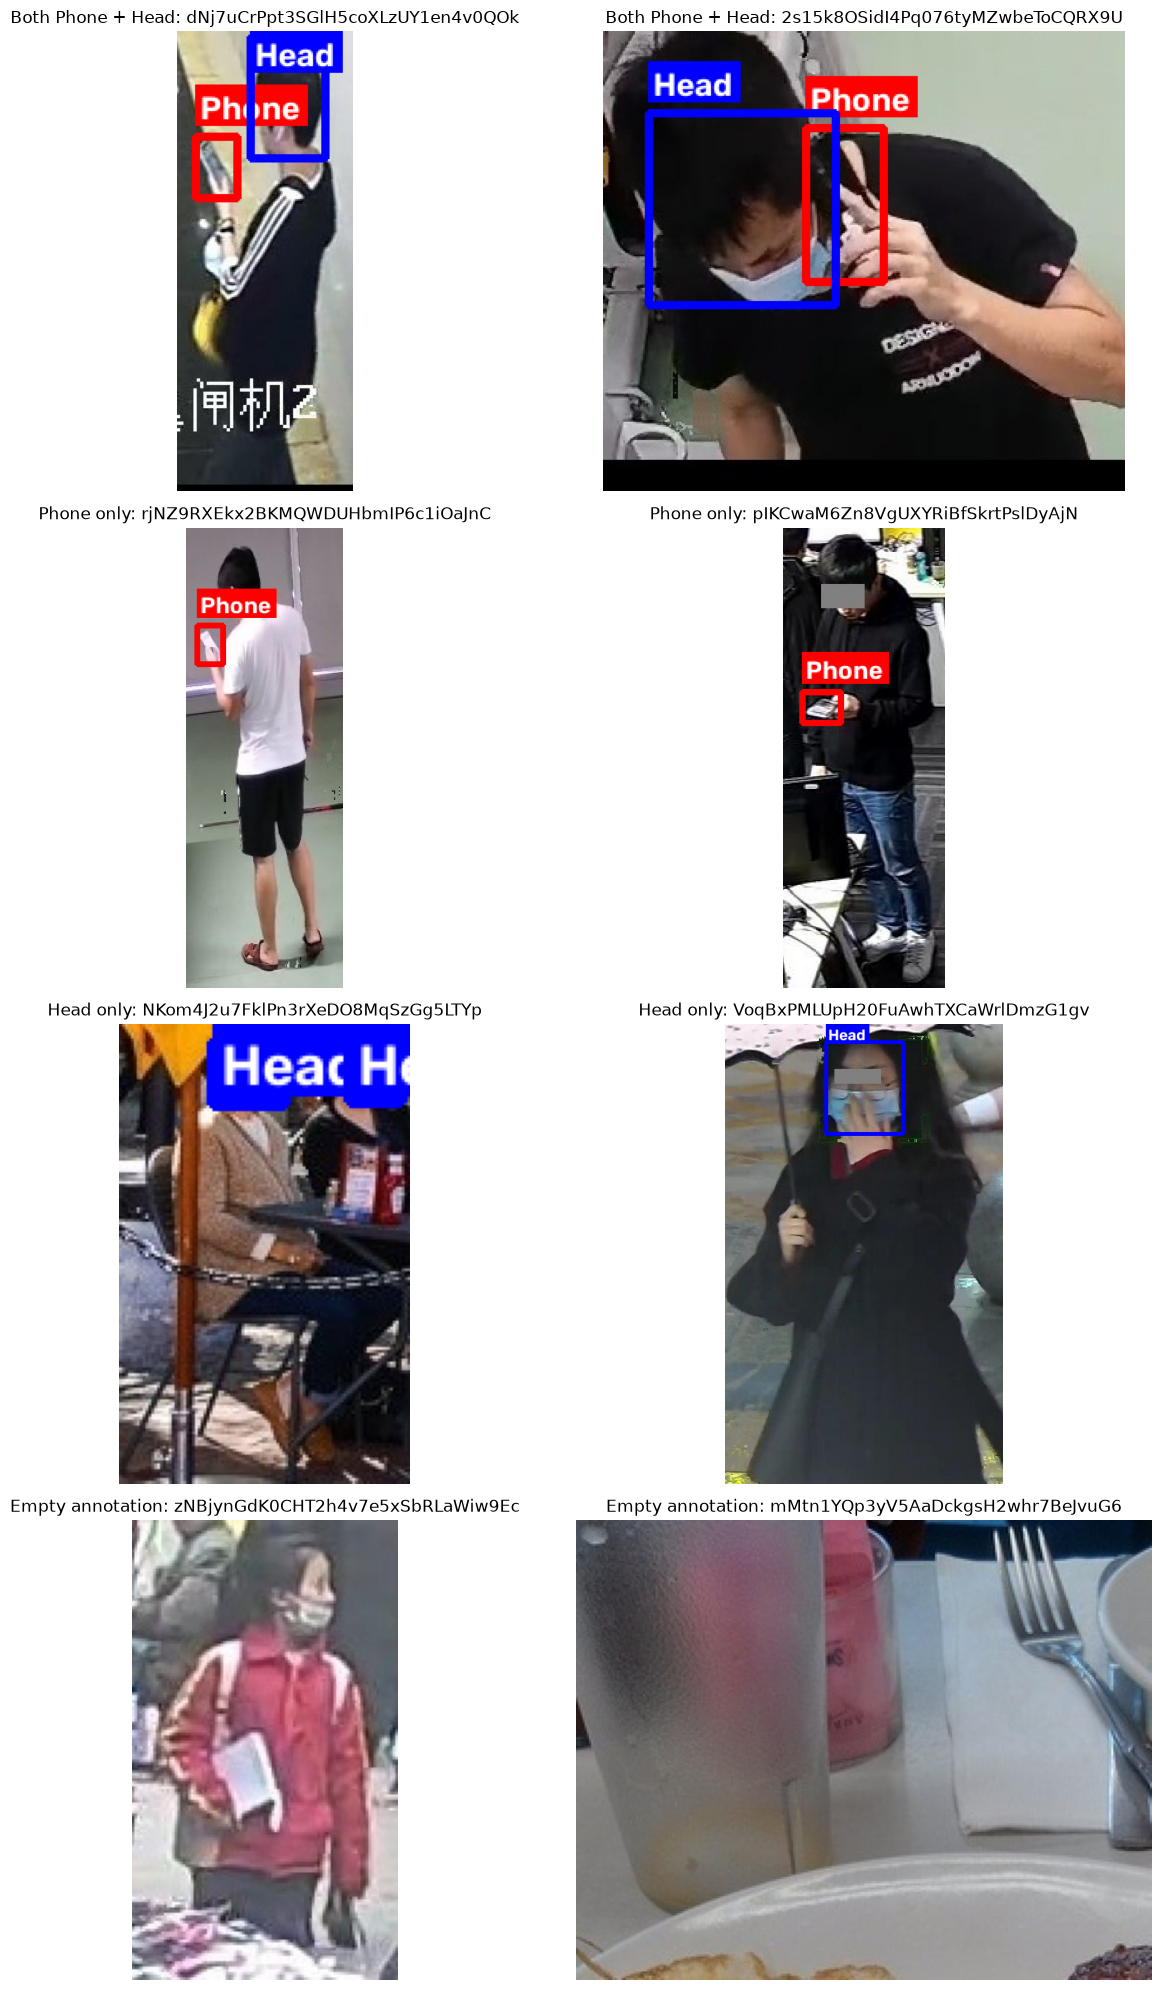

In [5]:
def yolo_to_pixels(box, width, height):
    """Convert (cx, cy, w, h) in normalized YOLO coordinates to pixel bounds."""
    cx, cy, bw, bh = box
    x1 = int(round((cx - bw / 2) * width))
    y1 = int(round((cy - bh / 2) * height))
    x2 = int(round((cx + bw / 2) * width))
    y2 = int(round((cy + bh / 2) * height))

    return (
        max(0, min(width - 1, x1)),
        max(0, min(height - 1, y1)),
        max(0, min(width - 1, x2)),
        max(0, min(height - 1, y2)),
    )


def load_original_annotation(image_path, label_paths):
    boxes = []
    for label_path in label_paths:
        parsed, _ = parse_label_file(label_path)
        boxes.extend(parsed)
    return boxes


# Build deterministic candidate groups from the original/raw dataset.
candidates = {
    "Both Phone + Head": [],
    "Phone only": [],
    "Head only": [],
    "Empty annotation": [],
}

for split in OFFICIAL_SPLIT_NAMES:
    if split not in indexed_splits:
        continue

    item = indexed_splits[split]
    for stem, image_paths in item["images_by_stem"].items():
        if len(image_paths) != 1:
            continue

        image_path = image_paths[0]
        boxes = load_original_annotation(
            image_path,
            item["labels_by_stem"].get(stem, []),
        )
        class_ids = {box["class_id"] for box in boxes}

        if class_ids == {0, 1}:
            candidates["Both Phone + Head"].append((image_path, boxes))
        elif class_ids == {0}:
            candidates["Phone only"].append((image_path, boxes))
        elif class_ids == {1}:
            candidates["Head only"].append((image_path, boxes))
        elif not boxes:
            candidates["Empty annotation"].append((image_path, boxes))

rng = random.Random(RANDOM_SEED)
for category_samples in candidates.values():
    rng.shuffle(category_samples)

visualization_samples = []
for category, category_samples in candidates.items():
    # Include up to two samples per category when available.
    for image_path, boxes in category_samples[:2]:
        visualization_samples.append((category, image_path, boxes))

if not visualization_samples:
    print("No original images were available for annotation visualization.")
else:
    columns = 2
    rows = int(np.ceil(len(visualization_samples) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(14, 5 * rows))
    axes = np.asarray(axes).reshape(-1)

    for ax, (category, image_path, boxes) in zip(axes, visualization_samples):
        original_bgr = cv2.imread(str(image_path))
        if original_bgr is None:
            ax.axis("off")
            ax.set_title(f"{category}\nUnreadable image")
            continue

        # cv2.imread creates a copy; converting it also keeps the original file unchanged.
        annotated = cv2.cvtColor(original_bgr.copy(), cv2.COLOR_BGR2RGB)
        height, width = annotated.shape[:2]

        for box in boxes:
            class_id = box["class_id"]
            x1, y1, x2, y2 = yolo_to_pixels(box["xywh"], width, height)

            if class_id == 0:
                color = (255, 0, 0)       # RGB red
                label = "Phone"
            elif class_id == 1:
                color = (0, 0, 255)       # RGB blue
                label = "Head"
            else:
                continue

            cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 3)
            (text_width, text_height), baseline = cv2.getTextSize(
                label,
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65,
                2,
            )
            text_x = x1
            text_y = max(text_height + 5, y1 - 8)
            cv2.rectangle(
                annotated,
                (text_x, text_y - text_height - 5),
                (text_x + text_width + 6, text_y + baseline),
                color,
                -1,
            )
            cv2.putText(
                annotated,
                label,
                (text_x + 3, text_y - 2),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65,
                (255, 255, 255),
                2,
                cv2.LINE_AA,
            )

        ax.imshow(annotated)
        ax.set_title(f"{category}: {image_path.stem}")
        ax.axis("off")

    for ax in axes[len(visualization_samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## 5. Prepare Phone-Only Annotations

This cell copies source images and creates empty label files for images with no valid Phone annotation. It does not modify `data/raw/`.

In [6]:
if RAW_ROOT.resolve() == PROCESSED_ROOT.resolve() or RAW_ROOT.resolve() in PROCESSED_ROOT.resolve().parents:
    raise RuntimeError("Processed output must not be inside or equal to data/raw.")

for split in OFFICIAL_SPLIT_NAMES:
    (PROCESSED_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (PROCESSED_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

processed_records = []
copy_errors = []

for split in OFFICIAL_SPLIT_NAMES:
    if split not in indexed_splits:
        continue
    item = indexed_splits[split]
    phone_images = 0

    for stem, image_paths in item["images_by_stem"].items():
        if len(image_paths) != 1:
            copy_errors.append(f"Skipping split {split}, duplicate image stem {stem}")
            continue

        source_image = image_paths[0]
        destination_image = PROCESSED_ROOT / "images" / split / source_image.name
        try:
            shutil.copy2(source_image, destination_image)
        except Exception as exc:
            copy_errors.append(f"Could not copy {source_image}: {exc}")
            continue

        phone_boxes = []
        for label_path in item["labels_by_stem"].get(stem, []):
            parsed, _ = parse_label_file(label_path)
            phone_boxes.extend(box["xywh"] for box in parsed if box["class_id"] == 0)

        destination_label = PROCESSED_ROOT / "labels" / split / f"{stem}.txt"
        if phone_boxes:
            phone_images += 1
            with destination_label.open("w", encoding="utf-8", newline="\n") as handle:
                for x, y, w, h in phone_boxes:
                    handle.write(f"0 {x:.10f} {y:.10f} {w:.10f} {h:.10f}\n")
        else:
            destination_label.write_text("", encoding="utf-8")

    processed_records.append({"split": split,
                              "images": len(list((PROCESSED_ROOT / "images" / split).glob("*"))),
                              "phone_images": phone_images})

print(pd.DataFrame(processed_records).to_string(index=False))
if copy_errors:
    print("Copy/write issues:")
    for error in copy_errors: print("-", error)

split  images  phone_images
train   18800          8358
  val    1730           795
 test    2349          1102


## 6. Create `data.yaml`

In [7]:
if IS_KAGGLE:
    dataset_path = "/kaggle/working/phone_detection"
else:
    dataset_path = "data/processed/phone_detection"

data_yaml = (
    "# YOLO phone-only dataset configuration\n"
    f"path: {dataset_path}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n\n"
    "nc: 1\n"
    "names: ['phone']\n"
)
(PROCESSED_ROOT / "data.yaml").write_text(data_yaml, encoding="utf-8")
print((PROCESSED_ROOT / "data.yaml").read_text(encoding="utf-8"))

# YOLO phone-only dataset configuration
path: data/processed/phone_detection
train: images/train
val: images/val
test: images/test

nc: 1
names: ['phone']



## 7. Final Dataset Validation

This cell checks image/label correspondence, class IDs, normalized coordinates, empty labels, cross-split duplicates, and the source-image count.

In [8]:
validation_errors = []
processed_images_by_split = {}
all_processed_stems = defaultdict(list)

for split in OFFICIAL_SPLIT_NAMES:
    image_dir = PROCESSED_ROOT / "images" / split
    label_dir = PROCESSED_ROOT / "labels" / split
    images = sorted(p for p in image_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    labels = sorted(p for p in label_dir.rglob("*") if p.is_file() and p.suffix.lower() == ".txt")
    processed_images_by_split[split] = images

    image_stems = {p.stem: p for p in images}
    label_stems = {p.stem: p for p in labels}
    for stem in image_stems:
        all_processed_stems[stem].append(split)

    missing = sorted(set(image_stems) - set(label_stems))
    unmatched = sorted(set(label_stems) - set(image_stems))
    if missing:
        validation_errors.append(f"{split}: images missing label files: {missing[:10]}")
    if unmatched:
        validation_errors.append(f"{split}: label files missing images: {unmatched[:10]}")

    empty_labels = 0
    phone_labels = 0
    for label_path in labels:
        content = label_path.read_text(encoding="utf-8")
        if not content.strip():
            empty_labels += 1
            continue
        phone_labels += 1

        for line_number, line in enumerate(content.splitlines(), start=1):
            fields = line.split()
            if len(fields) != 5:
                validation_errors.append(f"{label_path}: line {line_number} is not 5 fields")
                continue
            try:
                class_id = int(fields[0])
                values = [float(v) for v in fields[1:]]
            except (ValueError, TypeError):
                validation_errors.append(f"{label_path}: line {line_number} contains non-numeric values")
                continue

            if class_id != 0:
                validation_errors.append(f"{label_path}: line {line_number} has class {class_id}, expected 0")
            if len(values) != 4:
                validation_errors.append(f"{label_path}: line {line_number} has invalid value count")
            elif not all(np.isfinite(v) for v in values):
                validation_errors.append(f"{label_path}: line {line_number} contains non-finite values")
            elif any(v < 0 or v > 1 for v in values):
                validation_errors.append(f"{label_path}: line {line_number} has out-of-range coordinates")
            elif values[2] <= 0 or values[3] <= 0:
                validation_errors.append(f"{label_path}: line {line_number} has non-positive size")

    print(f"{split}: images={len(images)}, labels={len(labels)}, empty_labels={empty_labels}, phone_labels={phone_labels}")

cross_split_duplicates = {stem: splits for stem, splits in all_processed_stems.items() if len(set(splits)) > 1}
if cross_split_duplicates:
    validation_errors.append(f"Cross-split duplicate stems: {cross_split_duplicates}")

processed_image_total = sum(len(paths) for paths in processed_images_by_split.values())
source_image_total = len(all_raw_images)
if processed_image_total != source_image_total:
    validation_errors.append(f"Processed image count {processed_image_total} != source image count {source_image_total}")

print("\nFinal validation:")
print("Raw images:", source_image_total)
print("Processed images:", processed_image_total)
print("Cross-split duplicate stems:", len(cross_split_duplicates))
print("Validation issues:", len(validation_errors))
if validation_errors:
    for error in validation_errors[:50]: print("-", error)
else:
    print("All final validation checks passed.")

print("\nExpected output structure:")
print("data/processed/phone_detection/")
print("├── images/{train,val,test}/")
print("├── labels/{train,val,test}/")
print("└── data.yaml")

train: images=18800, labels=18800, empty_labels=10442, phone_labels=8358
val: images=1730, labels=1730, empty_labels=935, phone_labels=795
test: images=2349, labels=2349, empty_labels=1247, phone_labels=1102

Final validation:
Raw images: 22879
Processed images: 22879
Cross-split duplicate stems: 0
Validation issues: 0
All final validation checks passed.

Expected output structure:
data/processed/phone_detection/
├── images/{train,val,test}/
├── labels/{train,val,test}/
└── data.yaml


## Raw Dataset Issue Summary

The notebook automatically detects Kaggle datasets mounted under `/kaggle/input`. It preserves official `train`, `val`, and `test` splits and creates `/kaggle/working/phone_detection/` when running on Kaggle. Locally, it writes to `data/processed/phone_detection/`.

If Kaggle mounts multiple datasets, set `PHONE_RAW_ROOT` in a code cell before rerunning setup.

Some raw label rows contain multiple boxes on one line. The notebook reports these as malformed and interprets complete 5-field chunks explicitly. It does not generate labels from heuristics.

## Final Annotation Visualization (Run After Dataset Preparation)

This verification step uses the original/raw dataset, because it contains the original class `0 = Phone` and class `1 = Head` annotations. It displays temporary annotated copies without saving or modifying any image.


Available verification categories:
- Both classes: 9888 sample(s) found
- Phone only: 367 sample(s) found
- Head only: 12164 sample(s) found
- Empty annotation: 460 sample(s) found


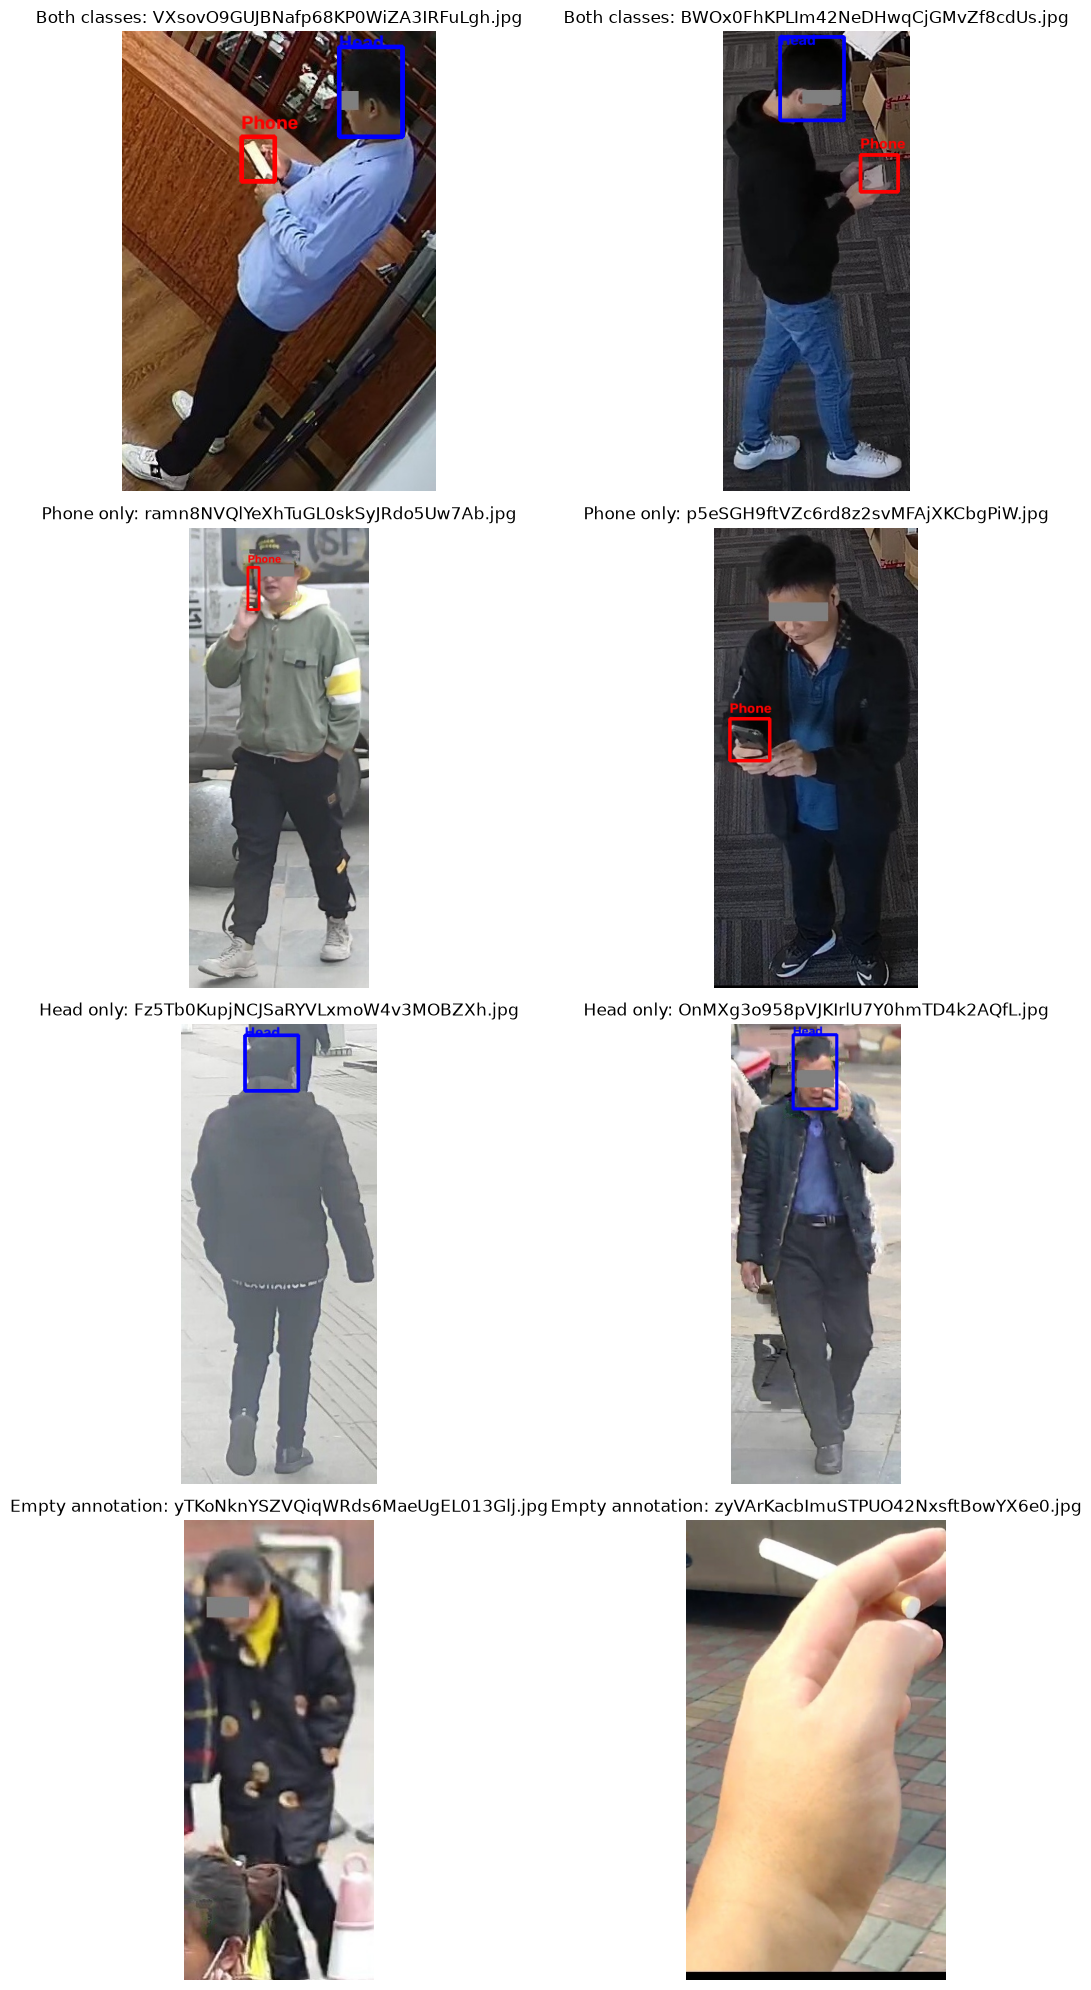

In [9]:
import random

# -----------------------------------------------------------------------------
# Post-run annotation verification
# -----------------------------------------------------------------------------
# Purpose:
# - Verify normalized YOLO annotations against the original images.
# - Include both-class, phone-only, head-only, and empty annotation samples.
# - Never overwrite or permanently annotate the original image files.

FINAL_VISUALIZATION_COLORS = {
    0: ((255, 0, 0), "Phone"),  # RGB red
    1: ((0, 0, 255), "Head"),   # RGB blue
}


def verify_yolo_box_pixels(box, image_width, image_height):
    x_center, y_center, box_width, box_height = box
    center_x = x_center * image_width
    center_y = y_center * image_height
    pixel_width = box_width * image_width
    pixel_height = box_height * image_height

    return (
        int(round(center_x - pixel_width / 2)),
        int(round(center_y - pixel_height / 2)),
        int(round(center_x + pixel_width / 2)),
        int(round(center_y + pixel_height / 2)),
    )


verification_groups = {
    "Both classes": [],
    "Phone only": [],
    "Head only": [],
    "Empty annotation": [],
}

if "indexed_splits" not in globals():
    print(
        "Skipping verification: `indexed_splits` is not defined. "
        "Run the dataset split-discovery/preparation cell first."
    )
else:
    for split, item in indexed_splits.items():
        for stem, image_paths in item["images_by_stem"].items():
            if len(image_paths) != 1:
                continue

            image_path = image_paths[0]
            boxes = []

            for label_path in item["labels_by_stem"].get(stem, []):
                parsed_boxes, _ = parse_label_file(label_path)
                boxes.extend(parsed_boxes)

            present_classes = {box["class_id"] for box in boxes}

            if present_classes == {0, 1}:
                verification_groups["Both classes"].append((image_path, boxes))
            elif present_classes == {0}:
                verification_groups["Phone only"].append((image_path, boxes))
            elif present_classes == {1}:
                verification_groups["Head only"].append((image_path, boxes))
            elif not boxes:
                verification_groups["Empty annotation"].append((image_path, boxes))

verification_rng = random.Random(RANDOM_SEED)
verification_samples = []
for category, category_samples in verification_groups.items():
    verification_rng.shuffle(category_samples)
    verification_samples.extend(
        (category, image_path, boxes)
        for image_path, boxes in category_samples[:2]
    )

print("Available verification categories:")
for category, category_samples in verification_groups.items():
    print(f"- {category}: {len(category_samples)} sample(s) found")

if verification_samples:
    cols = 2
    rows = int(np.ceil(len(verification_samples) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5 * rows))
    axes = np.asarray(axes).reshape(-1)

    for ax, (category, image_path, boxes) in zip(axes, verification_samples):
        original_bgr = cv2.imread(str(image_path))
        if original_bgr is None:
            ax.axis("off")
            ax.set_title(f"{category}\nCould not read image")
            continue

        # Create a temporary copy; original_bgr is never written back to disk.
        annotated_rgb = cv2.cvtColor(original_bgr.copy(), cv2.COLOR_BGR2RGB)
        image_height, image_width = annotated_rgb.shape[:2]

        for box in boxes:
            class_id = box["class_id"]
            if class_id not in FINAL_VISUALIZATION_COLORS:
                continue

            color, label = FINAL_VISUALIZATION_COLORS[class_id]
            x1, y1, x2, y2 = verify_yolo_box_pixels(
                box["xywh"], image_width, image_height
            )
            x1 = max(0, min(image_width - 1, x1))
            y1 = max(0, min(image_height - 1, y1))
            x2 = max(0, min(image_width - 1, x2))
            y2 = max(0, min(image_height - 1, y2))

            cv2.rectangle(annotated_rgb, (x1, y1), (x2, y2), color, 3)
            cv2.putText(
                annotated_rgb,
                label,
                (x1, max(18, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65,
                color,
                2,
                cv2.LINE_AA,
            )

        ax.imshow(annotated_rgb)
        ax.set_title(f"{category}: {image_path.name}")
        ax.axis("off")

    for ax in axes[len(verification_samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No images found for visualization. Run the split-discovery and annotation-parsing cells first.")


## Final Processed Dataset Structure Check

This final check validates the exact YOLO phone-only output structure. It does not create, copy, or modify any dataset files.


In [10]:
# Verify the final processed dataset contract without changing any files.
expected_splits = ("train", "val", "test")
expected_directories = [
    PROCESSED_ROOT / "images",
    PROCESSED_ROOT / "labels",
    *(PROCESSED_ROOT / "images" / split for split in expected_splits),
    *(PROCESSED_ROOT / "labels" / split for split in expected_splits),
]

structure_errors = [
    f"Missing directory: {directory}"
    for directory in expected_directories
    if not directory.is_dir()
]

label_errors = []
processed_counts = []
for split in expected_splits:
    image_dir = PROCESSED_ROOT / "images" / split
    label_dir = PROCESSED_ROOT / "labels" / split
    images = sorted(
        path for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ) if image_dir.is_dir() else []
    labels = sorted(label_dir.glob("*.txt")) if label_dir.is_dir() else []

    image_stems = {path.stem for path in images}
    label_stems = {path.stem for path in labels}
    missing_labels = image_stems - label_stems
    unmatched_labels = label_stems - image_stems
    if missing_labels:
        label_errors.append(f"{split}: missing labels for {sorted(missing_labels)[:5]}")
    if unmatched_labels:
        label_errors.append(f"{split}: labels without images {sorted(unmatched_labels)[:5]}")

    class_ids = set()
    for label_path in labels:
        for line_number, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), 1):
            if not line.strip():
                continue
            fields = line.split()
            if len(fields) != 5:
                label_errors.append(f"{label_path}: line {line_number} must contain 5 fields")
                continue
            try:
                class_ids.add(int(fields[0]))
            except ValueError:
                label_errors.append(f"{label_path}: line {line_number} has an invalid class id")

    if class_ids != {0} and class_ids:
        label_errors.append(f"{split}: processed labels contain unexpected classes {sorted(class_ids)}")

    processed_counts.append({
        "split": split,
        "images": len(images),
        "labels": len(labels),
        "empty_labels": sum(
            not label_path.read_text(encoding="utf-8").strip()
            for label_path in labels
        ),
    })

data_yaml_path = PROCESSED_ROOT / "data.yaml"
if not data_yaml_path.is_file():
    structure_errors.append(f"Missing file: {data_yaml_path}")
else:
    data_yaml_text = data_yaml_path.read_text(encoding="utf-8")
    required_yaml_entries = (
        "train: images/train",
        "val: images/val",
        "test: images/test",
        "nc: 1",
        "names: ['phone']",
    )
    for entry in required_yaml_entries:
        if entry not in data_yaml_text:
            structure_errors.append(f"data.yaml is missing: {entry}")

print(pd.DataFrame(processed_counts).to_string(index=False))
print("\nExpected structure:")
print("data/processed/phone_detection/{images,labels}/{train,val,test}/")
print("data/processed/phone_detection/data.yaml")
print("\nStructure errors:", len(structure_errors))
print("Label errors:", len(label_errors))
if structure_errors or label_errors:
    for error in structure_errors + label_errors:
        print("-", error)
    raise RuntimeError("Processed dataset structure validation failed.")
print("Processed phone-only dataset structure is valid.")


split  images  labels  empty_labels
train   18800   18800         10442
  val    1730    1730           935
 test    2349    2349          1247

Expected structure:
data/processed/phone_detection/{images,labels}/{train,val,test}/
data/processed/phone_detection/data.yaml

Structure errors: 0
Label errors: 0
Processed phone-only dataset structure is valid.
